# Covered-Bond Cover-Pool Stress & Overcollateralisation with VAE Scenarios

A covered bond is protected by a ring-fenced pool of mortgages, and the question for its investors is whether that pool would still cover the bonds if the issuing bank failed and the economy turned. The answer depends on which scenarios are considered plausible. This notebook stresses a real mortgage pool for two years after an issuer default and compares three ways of generating the economic scenarios.

**What it does.** It builds a cover pool of 20,000 performing U.S. mortgages from the Freddie Mac loan-level data, issues a five-year fixed-rate covered bond against it, and stresses the pool for 24 months after a hypothetical issuer default.

Joint paths of house prices, unemployment, the mortgage rate and the 5-year Treasury yield are generated by a **variational autoencoder (VAE)** trained on 39 years of U.S. data. They are compared with a Gaussian generator, a historical bootstrap and the Fed's 2026 severely adverse scenario.

For each scenario the notebook tracks defaults, prepayments, LTV-capped eligible collateral, cash and coupons. It then reports nominal and NPV overcollateralisation, and the initial OC needed to stay covered with 99% and 99.5% confidence.

**Data.** The Freddie Mac Single-Family Loan-Level Dataset (vintages 2018–2023, loans active at the last reporting month, which form the cover pool), Fannie Mae Single-Family Loan Performance data (2005–2008 acquisitions, which bring the crisis into the default model), FRED (Case-Shiller national and FHFA state house price indices, unemployment rate, 30-year mortgage rate, 5-year Treasury yield) and the Fed's 2026 supervisory scenarios.

**Methods.** A VAE on 24-month windows of standardised monthly changes (PyTorch), with multivariate Gaussian and moving-block bootstrap benchmarks.

The pool runs off cohort by cohort, with a default hazard driven by LTV and unemployment estimated on 20 million loan-months that include the 2008–2012 crisis, an S-curve prepayment function, an 80% LTV eligibility cap, lagged recoveries and an NPV test at market rates.

**Key output.** A comparison of the generators' tails, the distribution of nominal and NPV OC at 24 months, the breakeven initial OC, and how much of the outcome comes from house prices against rates.

## 1. What a covered bond's cover pool must survive

A covered bond is a bank bond with **dual recourse**: to the issuer and, if the issuer fails, to a ring-fenced pool of mortgages (the cover pool). Investors' protection is the **overcollateralisation** of that pool:

$$\text{OC}_t=\frac{\text{eligible cover assets}_t}{\text{covered bonds outstanding}_t}-1.$$

Covered-bond frameworks (the EU's CRR Article 129, the UK RCB regime, U.S. proposals) and rating agencies add two refinements that this notebook applies:

- **LTV cap.** A residential mortgage counts only up to 80% of the current indexed property value, so a house-price fall reduces eligible collateral even when nobody defaults. Loans 90+ days past due are excluded.
- **NPV test.** The present value of the pool's cash flows must exceed the present value of the bonds' cash flows at current market rates. A pool of long-duration fixed-rate mortgages funding a five-year bullet bond loses NPV cover when rates rise.

The question for the risk officer: **how much OC must the issuer post today so the bondholders remain covered in 99% (or 99.5%) of plausible two-year scenarios after the issuer defaults?** The answer is only as good as the scenario generator, which is why three generators are compared.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import torch
from scipy import stats
from sklearn.mixture import GaussianMixture

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
POOL_N = 20_000  # loans in the cover pool
HORIZON = 24  # months of run-off after the issuer default
WINDOW = 24  # length of the scenario paths the VAE learns
N_SCEN = 10_000
# eligibility: loan counts up to 80% of the indexed property value
LTV_CAP = 0.80
# nominal OC at issuance (share of eligible assets above bond principal)
OC_START = 0.10
BOND_TERM_Y = 5
BOND_SPREAD = 0.0050  # covered-bond spread over the 5-year Treasury
# distressed sale discount and liquidation costs (share of balance)
SALE_HAIRCUT, COSTS = 0.25, 0.05
RECOVERY_LAG = 12  # months from default to recovery cash
HIGH_LTV = 70  # threshold for the second, riskier cover pool
FED = "https://www.federalreserve.gov/supervisionreg/files/2026_Final_Supervisory_{}_Domestic.csv"

print(
    f"duckdb {duckdb.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

duckdb 1.5.6 · torch 2.14.1+cu130 · run on 2026-10-28


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Freddie Mac Single-Family Loan-Level Dataset (sample files)
# Download manually (free registration, non-commercial licence):
# https://freddiemac.embs.com/FLoan/Data/download.php
# → "Sample Dataset" → sample_YYYY.zip, saved in data/freddie_mac/ at the repo
# root.
# The files are licensed and are never committed: data/ is in .gitignore.
import zipfile


def find_shared_data(name):
    """
    Find data/<name> in this project's folder or any folder above it, up to the
    repo root (works with sub-folders).
    """
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
        if (d / ".git").exists():
            break
    return None


FREDDIE_DIR = find_shared_data("freddie_mac")
if FREDDIE_DIR is None or not list(FREDDIE_DIR.glob("sample_*.zip")):
    raise FileNotFoundError(
        "Put the Freddie Mac sample_YYYY.zip files in FIN/data/freddie_mac/"
        " (see the link above)."
    )
FM_TXT = DATA_DIR / "freddie_txt"
FM_TXT.mkdir(exist_ok=True)
for z in sorted(FREDDIE_DIR.glob("sample_*.zip")):
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))

ORIG_COLS = [
    "credit_score",
    "first_pay_date",
    "first_time_buyer",
    "maturity_date",
    "msa",
    "mi_pct",
    "n_units",
    "occupancy",
    "cltv",
    "dti",
    "orig_upb",
    "ltv",
    "orig_rate",
    "channel",
    "ppm_flag",
    "amort_type",
    "state",
    "prop_type",
    "zip3",
    "loan_id",
    "purpose",
    "orig_term",
    "n_borrowers",
    "seller_servicer",
    "super_conforming",
    "pre_relief_id",
    "program",
    "relief_refi",
    "valuation_method",
    "io_flag",
    "mi_cancel",
]
PERF_COLS = {
    0: "loan_id",
    1: "period",
    2: "upb",
    3: "dq",
    4: "age",
    5: "months_left",
    7: "mod_flag",
    8: "zb_code",
    9: "zb_date",
    10: "rate",
    21: "actual_loss",
    25: "eltv",
    26: "zb_upb",
    29: "assistance",
}


def freddie_con():
    con = duckdb.connect(
        str(DATA_DIR / "freddie.duckdb")
    )  # tables on disk, not in the notebook's memory
    con.execute("SET enable_progress_bar = false")
    con.execute("SET memory_limit = '2GB'")
    orig_sel = ", ".join(
        f"column{i:02d} AS {c}" for i, c in enumerate(ORIG_COLS)
    )
    con.execute(
        f"""CREATE OR REPLACE VIEW orig AS SELECT {orig_sel}
                    FROM read_csv('{(FM_TXT / "sample_orig_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    perf_sel = ", ".join(f"column{i:02d} AS {c}" for i, c in PERF_COLS.items())
    con.execute(
        f"""CREATE OR REPLACE VIEW perf AS SELECT {perf_sel}
                    FROM read_csv('{(FM_TXT / "sample_perf_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    return con


# --- Fannie Mae Single-Family Loan Performance data, 2005-2008 acquisitions
# Download manually (free registration): https://capitalmarkets.fanniemae.com
# → Single-Family Loan Performance Data → quarterly files 2005Q1 ... 2008Q4,
# saved as data/fannie_mae/2005Q1.zip ... at the repo root. The first run
# builds a sample in the Freddie Mac sample format (12,500 loans per quarter,
# 50,000 per vintage, monthly history) in data/fannie_mae/sample/ and reuses
# it afterwards. The files are licensed and are never committed.
import random


def _ym(s):
    return s[2:] + s[:2] if len(s) == 6 else ""


def _num(s, d=0.0):
    try:
        return float(s)
    except ValueError:
        return d


def fannie_quarter_to_sample(zip_path, yy, q, out_dir, keep=12_500,
                             share=0.08):
    """Filter one quarterly file (loan id mod 1000 < 80), draw `keep` loans
    and append them to sample_orig_20yy.txt / sample_perf_20yy.txt."""
    with zipfile.ZipFile(zip_path) as zf:
        name = zf.namelist()[0]
        lines = []
        with zf.open(name) as f:
            for raw in f:
                line = raw.decode("latin-1")
                lid = line.split("|", 3)[1]
                if int(lid) % 1000 < share * 1000:
                    lines.append(line)
    ids, seen = [], set()
    for line in lines:
        i = line.split("|", 3)[1]
        if i not in seen:
            seen.add(i)
            ids.append(i)
    random.seed(int(f"20{yy}{q}"))
    chosen = set(random.sample(ids, min(keep, len(ids))))
    new_id = {i: f"F{yy}Q{q}{k:07d}" for k, i in enumerate(sorted(chosen))}
    fo = open(out_dir / f"sample_orig_20{yy}.txt", "a")
    fp = open(out_dir / f"sample_perf_20{yy}.txt", "a")
    done, last_age = set(), {}
    for line in lines:
        x = line.rstrip("\n").split("|")
        lid = x[1]
        if lid not in chosen:
            continue
        p = lambda k: x[k - 1] if k - 1 < len(x) else ""
        nid = new_id[lid]
        if lid not in done:
            done.add(lid)
            purpose = {"P": "P", "C": "C", "R": "N"}.get(p(27), "9")
            o = [p(24) or "9999", _ym(p(15)),
                 p(26) if p(26) in ("Y", "N") else "9", _ym(p(19)), p(32),
                 p(34) or "0", p(29), p(30), p(21) or "999", p(23) or "999",
                 str(int(_num(p(10)))), p(20) or "999", p(8), p(4) or "9",
                 p(36) or "N", p(35) or "FRM", p(31), p(28), p(33), nid,
                 purpose, p(13), p(22) or "99", (p(5) or "OTHER").upper(),
                 p(87) or "N", "", p(79), p(103) or "N", p(86) or "9",
                 p(37) or "N", p(43) or "9999"]
            fo.write("|".join(o) + "\n")
        per, zb, upb = _ym(p(3)), p(44), _num(p(12))
        age = int(_num(p(16), -1))
        if age < 0:
            age = last_age.get(lid, -1) + 1
        last_age[lid] = age
        if upb == 0 and not zb:         # masked in the first months
            upb = _num(p(11)) or _num(p(10))
        loss = ""
        if p(59) or p(60) or p(62):     # disposition: Freddie-style loss
            zbu, rate = _num(p(46)), _num(p(9)) or _num(p(8))
            lp, zd = _ym(p(51)), _ym(p(45)) or per
            gap = ((int(zd[:4]) - int(lp[:4])) * 12 + int(zd[4:])
                   - int(lp[4:])) if lp and zd else 0
            dai = zbu * rate / 1200 * max(gap - 1, 0)
            costs = sum(_num(p(k)) for k in (54, 55, 56, 57, 58))
            proceeds = sum(_num(p(k)) for k in (59, 60, 61, 62))
            loss = f"{proceeds - zbu - costs - dai:.2f}"
        r = [""] * 35
        r[0], r[1], r[2] = nid, per, f"{0.0 if zb else upb:.2f}"
        r[3] = "" if p(40) == "XX" else p(40)
        r[4], r[5] = str(age), p(18)
        r[7] = "Y" if p(42) == "Y" else ""
        r[8], r[9], r[10] = zb, _ym(p(45)), p(9) or p(8)
        r[11], r[12] = p(63) or "0.00", _ym(p(51))
        r[21], r[26], r[29] = loss, (p(46) if zb else ""), p(102)
        r[31] = f"{_num(p(110)) or (0.0 if zb else upb):.2f}"
        r[33] = (p(6) or "OTHER").upper()
        fp.write("|".join(r) + "\n")
    fo.close()
    fp.close()


def fannie_sample_zips():
    src = find_shared_data("fannie_mae")
    if src is None:
        return []
    out = src / "sample"
    if not list(out.glob("sample_*.zip")):
        quarters = sorted(src.glob("20??Q?.zip"))
        if not quarters:
            return []
        out.mkdir(exist_ok=True)
        tmp = DATA_DIR / "fannie_build"
        tmp.mkdir(exist_ok=True)
        for z in quarters:              # about 1-2 minutes per quarter
            print("sampling", z.name)
            fannie_quarter_to_sample(z, z.stem[2:4], z.stem[-1], tmp)
        for y in sorted({z.stem[:4] for z in quarters}):
            with zipfile.ZipFile(out / f"sample_{y}.zip", "w",
                                 zipfile.ZIP_DEFLATED) as zf:
                for kind in ["orig", "perf"]:
                    zf.write(tmp / f"sample_{kind}_{y}.txt",
                             f"sample_{kind}_{y}.txt")
    return sorted(out.glob("sample_*.zip"))


for z in fannie_sample_zips():
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))


## 3. Macro history and the VAE scenario generator

Four series, monthly, from January 1987 (the start of Case-Shiller): the log change of the seasonally adjusted national house price index, and the changes in unemployment, the 30-year mortgage rate and the 5-year Treasury yield. Each is standardised. A training example is a 24-month window of the four series (96 numbers); overlapping windows give about 440 examples.

The VAE compresses a window into a 6-dimensional latent code $z$ and reconstructs it, with a KL penalty that makes $z\sim N(0,I)$ a valid sampling distribution. Each output also has a learned noise level, floored at 0.3 standard deviations so that the decoder cannot simply memorise the 450 windows.

A diagnostic run holds out three blocks of windows (separated from the training windows by 24-month gaps) to show how far the model generalises beyond the episodes it has seen; the final model is then refitted on all windows for the same 2,000 full-batch epochs.

New scenarios are decoded from fresh draws of $z$. It can learn the non-Gaussian shape of history: house-price momentum (falls come in long runs), the co-movement of mortgage rates with Treasuries, and unemployment spikes. Benchmarks:

- **Gaussian:** a multivariate normal on the same 96-dimensional windows, using a shrunk covariance. It captures correlations and autocorrelation but has thin, symmetric tails.

**VAE + latent GMM:** a known weakness of VAEs trained on little data is that the encoded historical windows do not fill the $N(0,I)$ prior evenly; rare episodes (2007–11) sit in sparse corners of latent space that prior draws seldom reach. Fitting a 10-component Gaussian mixture to the encoded windows and sampling from it instead (ex-post density estimation, as in Ghosh et al., 2020) restores those regions while still generating new paths.

- **Block bootstrap:** the actual historical 24-month windows, drawn at random. It is realistic but can only replay the ~18 non-overlapping episodes in the record.

In [3]:
def fetch_macro():
    ids = {
        "hpi": "CSUSHPISA",
        "unrate": "UNRATE",
        "mort": "MORTGAGE30US",
        "ust5": "DGS5",
    }
    return pd.DataFrame({
        k: (
            fred.get_series(v, observation_start="1986-12-01")
            .resample("MS")
            .mean()
        )
        for k, v in ids.items()
    })


macro = cached("macro_c04", fetch_macro, max_age_hours=24 * 7).dropna()
chg = pd.DataFrame({
    "hpi": np.log(macro["hpi"]).diff() * 100,
    "unrate": macro["unrate"].diff(),
    "mort": macro["mort"].diff(),
    "ust5": macro["ust5"].diff(),
}).dropna()
VARS = list(chg)
mu, sd = chg.mean(), chg.std()
zc = ((chg - mu) / sd).to_numpy(np.float32)
# windows x (24*4), time-major
X = np.stack(
    [zc[i : i + WINDOW].reshape(-1) for i in range(len(zc) - WINDOW + 1)]
)
NOW = macro.iloc[-1]
print(
    f"Monthly data {chg.index.min():%Y-%m} –"
    f" {chg.index.max():%Y-%m} ({len(chg)} months) → {len(X)} overlapping"
    f" windows · latest: HPI {NOW['hpi']:.1f}, unemployment"
    f" {NOW['unrate']:.1f}%, mortgage {NOW['mort']:.2f}%, 5y UST"
    f" {NOW['ust5']:.2f}%"
)

Monthly data 1987-02 – 2026-08 (474 months) → 451 overlapping windows · latest: HPI 334.2, unemployment 4.1%, mortgage 6.67%, 5y UST 4.38%


In [4]:
class VAE(torch.nn.Module):
    def __init__(self, d, k=6, h=64):
        super().__init__()
        self.enc = torch.nn.Sequential(
            torch.nn.Linear(d, h),
            torch.nn.GELU(),
            torch.nn.Linear(h, h),
            torch.nn.GELU(),
        )
        self.mu, self.logvar = torch.nn.Linear(h, k), torch.nn.Linear(h, k)
        self.dec = torch.nn.Sequential(
            torch.nn.Linear(k, h),
            torch.nn.GELU(),
            torch.nn.Linear(h, h),
            torch.nn.GELU(),
            torch.nn.Linear(h, d),
        )
        # learned per-output noise, sampled at generation
        self.raw_noise = torch.nn.Parameter(torch.zeros(d))

    @property
    # floor at 0.3 s.d.: stops the decoder memorising windows
    def log_noise(self):
        return np.log(0.3) + torch.nn.functional.softplus(self.raw_noise)

    def forward(self, x):
        e = self.enc(x)
        m, lv = self.mu(e), self.logvar(e)
        z = m + torch.randn_like(m) * torch.exp(0.5 * lv)
        return self.dec(z), m, lv


Xt = torch.tensor(X)
# Time-block validation: three 40-window blocks held out, with a 24-window gap
# on each side so no month is shared
val_m, gap_m = np.zeros(len(X), bool), np.zeros(len(X), bool)
for st in [60, 200, 340]:
    val_m[st : st + 40] = True
    gap_m[max(0, st - WINDOW) : st] = True
    gap_m[st + 40 : st + 40 + WINDOW] = True
val_idx, tr_idx = np.where(val_m)[0], np.where(~val_m & ~gap_m)[0]
BETA, EPOCHS = 1.0, 2000


def neg_elbo(model, xb, sample=True):
    e = model.enc(xb)
    m, lv = model.mu(e), model.logvar(e)
    z = m + torch.randn_like(m) * torch.exp(0.5 * lv) if sample else m
    rec = model.dec(z)
    nll = (
        (
            0.5 * ((xb - rec) ** 2) * torch.exp(-2 * model.log_noise)
            + model.log_noise
        )
        .sum(1)
        .mean()
    )
    kl = (-0.5 * (1 + lv - m**2 - lv.exp()).sum(1)).mean()
    return nll + BETA * kl, kl


def train_vae(idx, monitor=None):
    torch.manual_seed(SEED)
    model = VAE(X.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-3)
    log = []
    for ep in range(EPOCHS):
        model.train()
        loss, kl = neg_elbo(model, Xt[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
        if monitor is not None and (ep % 25 == 0 or ep == EPOCHS - 1):
            model.eval()
            with torch.no_grad():
                v_loss, _ = neg_elbo(model, Xt[monitor], sample=False)
            log.append((ep, loss.item(), v_loss.item(), kl.item()))
    return model, log


# 1) diagnostic run with held-out blocks; 2) final model refitted on every
# window for the same number of epochs
_, hist_loss = train_vae(tr_idx, monitor=val_idx)
vae, _ = train_vae(np.arange(len(X)))
vae.eval()
hl = pd.DataFrame(
    hist_loss, columns=["epoch", "train", "validation", "KL"]
).set_index("epoch")
print(
    f"Diagnostic run on {len(tr_idx)} windows ({len(val_idx)} held out): final"
    f" train loss {hl['train'].iloc[-1]:.1f}, held-out"
    f" {hl['validation'].iloc[-1]:.1f} (best {hl['validation'].min():.1f} at"
    f" epoch {hl['validation'].idxmin()}), KL {hl['KL'].iloc[-1]:.1f} nats."
    f" Final VAE refitted on all {len(X)} windows."
)

Diagnostic run on 187 windows (120 held out): final train loss -63.2, held-out 294.3 (best 36.0 at epoch 100), KL 17.4 nats. Final VAE refitted on all 451 windows.


In [5]:
rng = np.random.default_rng(SEED)


# standardised windows -> level paths (scenario x month x variable)
def to_paths(Z):
    d = Z.reshape(len(Z), WINDOW, len(VARS)) * sd.to_numpy() + mu.to_numpy()
    lvl = np.empty_like(d)
    lvl[..., 0] = NOW["hpi"] * np.exp(np.cumsum(d[..., 0], 1) / 100)
    lvl[..., 1] = np.clip(NOW["unrate"] + np.cumsum(d[..., 1], 1), 2.5, None)
    lvl[..., 2] = np.clip(NOW["mort"] + np.cumsum(d[..., 2], 1), 2.0, None)
    lvl[..., 3] = np.clip(NOW["ust5"] + np.cumsum(d[..., 3], 1), 0.1, None)
    return lvl


vae.eval()
with torch.no_grad():
    zs = torch.randn(N_SCEN, 6)
    dec = vae.dec(zs) + torch.randn(N_SCEN, X.shape[1]) * torch.exp(
        vae.log_noise
    )
    # posterior means of all historical windows
    lat = vae.mu(vae.enc(Xt)).numpy()
warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn")
gmm = GaussianMixture(
    10, covariance_type="full", reg_covar=1e-4, random_state=SEED
).fit(lat)
z_g, _ = gmm.sample(N_SCEN)
with torch.no_grad():
    dec_g = vae.dec(torch.tensor(z_g, dtype=torch.float32)) + torch.randn(
        N_SCEN, X.shape[1]
    ) * torch.exp(vae.log_noise)
gens = {
    "VAE": to_paths(dec.numpy()),
    "VAE + latent GMM": to_paths(dec_g.numpy()),
}
cov = np.cov(X.T)
lam = 0.1
cov_s = (1 - lam) * cov + lam * np.diag(np.diag(cov))
gens["Gaussian"] = to_paths(rng.multivariate_normal(X.mean(0), cov_s, N_SCEN))
block_starts = rng.integers(0, len(X), N_SCEN)
gens["Historical bootstrap"] = to_paths(X[block_starts])


def fetch_fed():
    out = []
    for s in ["Baseline", "Severely_Adverse"]:
        out.append(
            pd.read_csv(
                io.StringIO(
                    requests.get(
                        FED.format(s), headers=BROWSER_HEADERS, timeout=60
                    ).text
                )
            ).astype(str)
        )
    return pd.concat(out, ignore_index=True)


fed = cached("fed_2026_domestic", fetch_fed, max_age_hours=24 * 30)
fsa = fed[fed["Scenario Name"].str.contains("Severely")].copy()
fsa["date"] = pd.PeriodIndex(
    fsa["Date"].str.replace(" ", ""), freq="Q"
).to_timestamp(how="end").normalize() - pd.offsets.MonthBegin(1)
fsa = fsa.set_index("date")[[
    "House Price Index (Level)",
    "Unemployment rate",
    "Mortgage rate",
    "5-year Treasury yield",
]].apply(pd.to_numeric)
fsa = (
    fsa.reindex(pd.date_range(fsa.index.min(), fsa.index.max(), freq="MS"))
    .interpolate()
    .iloc[:WINDOW]
)
rel = fsa.to_numpy()
fed_path = np.stack(
    [
        NOW["hpi"] * rel[:, 0] / rel[0, 0],
        NOW["unrate"] + rel[:, 1] - rel[0, 1],
        NOW["mort"] + rel[:, 2] - rel[0, 2],
        NOW["ust5"] + rel[:, 3] - rel[0, 3],
    ],
    -1,
)[None]
gens["Fed 2026 severely adverse"] = fed_path


def summarise(p):
    return {
        "HPI 24m change: mean %": (p[:, -1, 0] / NOW["hpi"] - 1).mean() * 100,
        "HPI: 1st pct %": np.percentile(p[:, -1, 0] / NOW["hpi"] - 1, 1) * 100,
        "P(HPI falls >10%) %": (
            (p[:, -1, 0] / NOW["hpi"] - 1) < -0.10
        ).mean() * 100,
        "unemployment: 99th pct of peak rise, pp": np.percentile(
            p[:, :, 1].max(1) - NOW["unrate"], 99
        ),
        "mortgage rate 24m change: 1st / 99th pct, pp": (
            f"{np.percentile(p[:, -1, 2] - NOW['mort'], 1):+.2f} /"
            f" {np.percentile(p[:, -1, 2] - NOW['mort'], 99):+.2f}"
        ),
        "corr(Δmortgage, Δ5y) at 24m": (
            np.corrcoef(p[:, -1, 2], p[:, -1, 3])[0, 1]
            if len(p) > 1
            else np.nan
        ),
        "corr(ΔHPI, Δunemployment) at 24m": (
            np.corrcoef(p[:, -1, 0], p[:, -1, 1])[0, 1]
            if len(p) > 1
            else np.nan
        ),
    }


# Non-overlapping historical windows as the reference for what history actually
# contains
hist_paths = to_paths(X)
gen_tab = pd.DataFrame({
    k: summarise(v)
    for k, v in {**gens, "History (all windows)": hist_paths}.items()
}).T
gen_tab

,HPI 24m change: mean %,HPI: 1st pct %,P(HPI falls >10%) %,"unemployment: 99th pct of peak rise, pp","mortgage rate 24m change: 1st / 99th pct, pp","corr(Δmortgage, Δ5y) at 24m","corr(ΔHPI, Δunemployment) at 24m"
VAE,9.81,-12.83,2.30,5.36,-3.19 / +3.02,0.74,-0.35
VAE + latent GMM,9.14,-18.23,5.23,10.77,-3.45 / +3.76,0.77,-0.42
Gaussian,9.24,-13.41,2.78,5.30,-3.00 / +2.58,0.86,-0.42
Historical bootstrap,9.12,-17.89,6.40,11.20,-2.12 / +4.07,0.92,-0.42
Fed 2026 severely adverse,-24.21,-24.21,100.00,4.10,-0.70 / -0.70,NaN,NaN
History (all windows),9.26,-17.87,6.21,11.20,-2.11 / +4.05,0.92,-0.40


## 4. The cover pool

The cover pool is a random draw of 20,000 loans from the Freddie Mac sample that are current (0 days past due) at the last reporting month, with their actual balance, note rate, remaining term and Freddie's estimated current LTV (ELTV, which uses an automated valuation of the property).

To keep the run-off fast across 10,000 scenarios, loans are grouped into 100 cohorts (20 ELTV bands × 5 note-rate bands); within a cohort, the balance-weighted LTV, rate and term are used.

**Default hazard calibration.** The monthly hazard of a first 90-day delinquency (outside forbearance) is measured by the prior month's mark-to-market LTV band and by unemployment six months earlier, on the 2005–08 Fannie Mae and 2018–23 Freddie Mac loans together (2005–2026, excluding 2020–21 when forbearance absorbed delinquencies). Freddie Mac publishes an estimated LTV; for the Fannie Mae loans it is rebuilt from the original LTV, the amortised balance and the FHFA house-price index of the property's state. A Poisson regression of defaults on the LTV band and unemployment, with loan-months as exposure, gives the LTV slope and the unemployment elasticity, both from loan data instead of an external series.

In [6]:
con = freddie_con()
last_per = con.execute("SELECT MAX(period) FROM perf").fetchone()[0]
pool = con.execute(f"""
SELECT p.loan_id, TRY_CAST(p.upb AS DOUBLE) AS upb, TRY_CAST(p.rate AS DOUBLE) AS rate, TRY_CAST(p.months_left AS INT) AS n_left,
       COALESCE(NULLIF(TRY_CAST(p.eltv AS DOUBLE), 999), TRY_CAST(o.ltv AS DOUBLE) * TRY_CAST(p.upb AS DOUBLE) / TRY_CAST(o.orig_upb AS DOUBLE)) AS eltv,
       TRY_CAST(o.credit_score AS INT) AS fico
FROM perf p JOIN orig o USING (loan_id)
WHERE p.period = '{last_per}' AND (p.dq = '0' OR p.dq = '00') AND substr(p.loan_id, 2, 2) >= '18'
ORDER BY p.loan_id""").df()
pool_all = pool[
    (pool["upb"] > 0) & pool["eltv"].between(1, 200) & (pool["n_left"] > 12)
]
hi = pool_all[pool_all["eltv"] >= HIGH_LTV]
POOLS = {
    "Seasoned pool": pool_all.sample(POOL_N, random_state=SEED),
    f"High-LTV pool (ELTV ≥ {HIGH_LTV}%)": hi.sample(
        min(POOL_N, len(hi)), random_state=SEED
    ),
}

# Default hazard by mark-to-market LTV and unemployment, on both periods.
# Fannie Mae publishes no estimated LTV: it is rebuilt from the original LTV,
# the amortised balance and the state house-price index (FRED).
states = [r[0] for r in con.execute(
    "SELECT DISTINCT state FROM orig WHERE state IS NOT NULL").fetchall()]


def fetch_state_hpi():
    out = {}
    for st in states:
        try:
            out[st] = fred.get_series(f"{st}STHPI")
        except Exception:
            pass
    return pd.DataFrame(out)


shpi = cached("fred_state_hpi", fetch_state_hpi, max_age_hours=24 * 30)
shpi.index = pd.to_datetime(shpi.index)
shpi = shpi.resample("MS").mean().interpolate().ffill()
shpi_long = (shpi.stack().rename("hpi").reset_index()
             .set_axis(["date", "state", "hpi"], axis=1))
shpi_long["per"] = shpi_long["date"].dt.year * 100 + shpi_long["date"].dt.month
con.register("shpi", shpi_long[["state", "per", "hpi"]])
un = macro["unrate"].copy()
con.register("un", pd.DataFrame({
    "per": (un.index + pd.DateOffset(months=6)).year * 100
    + (un.index + pd.DateOffset(months=6)).month,
    "u_lag6": un.to_numpy()}))
haz = con.execute("""
WITH p AS (SELECT loan_id, CAST(period AS INT) AS per, dq, zb_code, COALESCE(assistance, '') AS a,
                  TRY_CAST(eltv AS DOUBLE) AS eltv, TRY_CAST(upb AS DOUBLE) AS upb FROM perf),
fd AS (SELECT loan_id, MIN(per) AS d_per FROM p WHERE (dq NOT IN ('0', '00', '01', '1', '02', '2', 'RA') AND a <> 'F') OR zb_code IN ('02', '03', '09', '15') GROUP BY 1),
o AS (SELECT loan_id, state, TRY_CAST(ltv AS DOUBLE) AS ltv0, TRY_CAST(orig_upb AS DOUBLE) AS upb0,
             CAST(first_pay_date AS INT) - 1 AS per0 FROM orig),
x AS (SELECT p.loan_id, p.per, LAG(p.eltv) OVER w AS eltv_l, LAG(p.upb) OVER w AS upb_l, LAG(p.per) OVER w AS per_l,
             COALESCE(fd.d_per = p.per, FALSE)::INT AS d, fd.d_per
      FROM p LEFT JOIN fd USING (loan_id) WINDOW w AS (PARTITION BY p.loan_id ORDER BY p.per)),
y AS (SELECT x.*, COALESCE(NULLIF(x.eltv_l, 999), o.ltv0 * x.upb_l / o.upb0 * h0.hpi / h1.hpi) AS ltv_mtm, un.u_lag6
      FROM x JOIN o USING (loan_id)
      LEFT JOIN shpi h0 ON h0.state = o.state AND h0.per = o.per0
      LEFT JOIN shpi h1 ON h1.state = o.state AND h1.per = x.per_l
      LEFT JOIN un ON un.per = x.per)
SELECT LEAST(FLOOR(ltv_mtm / 10) * 10, 140) AS band, ROUND(u_lag6) AS u, COUNT(*) AS n, SUM(d) AS defaults
FROM y WHERE (d_per IS NULL OR per <= d_per) AND ltv_mtm BETWEEN 1 AND 250 AND u_lag6 IS NOT NULL
      AND (per < 202003 OR per > 202112)
GROUP BY 1, 2""").df()
con.close()
import statsmodels.api as sm

hz = haz[haz["n"] >= 2_000].copy()
Xh = sm.add_constant(pd.DataFrame({"ltv10": (hz["band"] + 5 - 80) / 10,
                                   "u": hz["u"] - 5}))
pois = sm.GLM(hz["defaults"], Xh, family=sm.families.Poisson(),
              exposure=hz["n"]).fit()
BETA_LTV, GAMMA_U = pois.params["ltv10"], pois.params["u"]
U_REF = 5.0
H0_AT80 = np.exp(pois.params["const"] + GAMMA_U * (NOW["unrate"] - U_REF))
band_tab = hz.groupby("band").apply(
    lambda g: pd.Series({"loan-months": g["n"].sum(),
                         "hazard bp/month": g["defaults"].sum()
                         / g["n"].sum() * 1e4}), include_groups=False)
print(
    f"Current loans at {last_per}: {len(pool_all):,}, of which"
    f" {len(hi):,} ({len(hi) / len(pool_all):.1%}) with ELTV ≥ {HIGH_LTV}%"
)
for name, p_ in POOLS.items():
    print(
        f"  {name}: {len(p_):,} loans, ${p_['upb'].sum() / 1e6:,.0f}mm, WA"
        f" rate {np.average(p_['rate'], weights=p_['upb']):.2f}%, "
        f"WA ELTV {np.average(p_['eltv'], weights=p_['upb']):.1f}%, WA"
        " remaining term"
        f" {np.average(p_['n_left'], weights=p_['upb']) / 12:.1f}y, "
        "WA FICO"
        f" {np.average(p_['fico'].fillna(p_['fico'].median()), weights=p_['upb']):.0f}"
    )
print(
    f"Default hazard (Poisson, 2005–26 excluding 2020–21): {BETA_LTV:+.3f}"
    f" log points per 10 LTV points (z {pois.tvalues['ltv10']:.0f}),"
    f" {GAMMA_U:+.3f} per pp of unemployment six months earlier (z"
    f" {pois.tvalues['u']:.0f}); {H0_AT80 * 1e4:.2f} bp/month at 80% LTV and"
    f" today's unemployment ({hz['n'].sum() / 1e6:.1f}mm loan-months)"
)
band_tab.style.format({"loan-months": "{:,.0f}", "hazard bp/month": "{:.2f}"})

Current loans at 202603: 167,918, of which 38,537 (22.9%) with ELTV ≥ 70%
  Seasoned pool: 20,000 loans, $4,906mm, WA rate 4.55%, WA ELTV 57.7%, WA remaining term 24.4y, WA FICO 753
  High-LTV pool (ELTV ≥ 70%): 20,000 loans, $6,383mm, WA rate 5.78%, WA ELTV 80.5%, WA remaining term 26.8y, WA FICO 752
Default hazard (Poisson, 2005–26 excluding 2020–21): +0.263 log points per 10 LTV points (z 97), +0.245 per pp of unemployment six months earlier (z 94); 10.87 bp/month at 80% LTV and today's unemployment (19.9mm loan-months)


,loan-months,hazard bp/month
band,,
0.000000,"168,658",3.32
10.000000,"527,502",3.01
20.000000,"1,063,310",3.66
30.000000,"1,656,033",4.47
40.000000,"2,340,045",5.78
50.000000,"2,806,273",7.91
60.000000,"3,107,427",11.67
70.000000,"3,773,092",13.93
80.000000,"2,557,027",23.71


In [7]:
def make_cohorts(p_):
    p_ = p_.copy()
    p_["ltv_band"] = pd.qcut(p_["eltv"].rank(method="first"), 20, labels=False)
    p_["rate_band"] = pd.qcut(p_["rate"].rank(method="first"), 5, labels=False)
    w = lambda g, c: np.average(g[c], weights=g["upb"])
    c_ = (
        p_.groupby(["ltv_band", "rate_band"])
        .apply(
            lambda g: pd.Series({
                "upb": g["upb"].sum(),
                "rate": w(g, "rate") / 100,
                "n_left": w(g, "n_left"),
                "ltv": w(g, "eltv") / 100,
                "n": len(g),
            }),
            include_groups=False,
        )
        .reset_index()
    )
    c_["value"] = c_["upb"] / c_["ltv"]
    return c_


COHORTS = {k: make_cohorts(v) for k, v in POOLS.items()}
BOND_CPN = NOW["ust5"] / 100 + BOND_SPREAD
for k, c_ in COHORTS.items():
    e0 = np.minimum(c_["upb"], LTV_CAP * c_["value"]).sum()
    print(
        f"{k}: {len(c_)} cohorts · balance ${c_['upb'].sum() / 1e6:,.0f}mm,"
        f" eligible ${e0 / 1e6:,.0f}mm ({e0 / c_['upb'].sum():.1%} after the"
        f" 80% LTV cap) · covered bonds ${e0 / (1 + OC_START) / 1e6:,.0f}mm"
    )
print(
    f"Covered bond: {BOND_TERM_Y}-year bullet, coupon {BOND_CPN:.2%} (5y UST"
    f" {NOW['ust5']:.2f}% + {BOND_SPREAD * 1e4:.0f} bp), nominal OC at"
    f" issuance {OC_START:.0%}"
)

Seasoned pool: 100 cohorts · balance $4,906mm, eligible $4,850mm (98.9% after the 80% LTV cap) · covered bonds $4,409mm
High-LTV pool (ELTV ≥ 70%): 100 cohorts · balance $6,383mm, eligible $6,145mm (96.3% after the 80% LTV cap) · covered bonds $5,586mm
Covered bond: 5-year bullet, coupon 4.88% (5y UST 4.38% + 50 bp), nominal OC at issuance 10%


## 5. Cover-pool run-off engine

For each scenario and month (vectorised over scenarios × cohorts):

1. **House prices** move each cohort's property value with the national index; LTV = balance / value.
2. **Default** hazard $h=h_{80}\exp\{\beta_\text{LTV}(\text{LTV}-80)/10+\gamma_u(u_t-u_0)\}$, capped at 5% a month. Defaulted balance leaves the eligible pool; after 12 months it returns as recovery cash $\max\{0,\min[B,(1-c)V]-k B\}$.
3. **Prepayment** follows an S-curve in the refinancing incentive (note rate minus the current mortgage rate), in line with Freddie Mac prepayment experience: about 6% CPR with no incentive, rising towards 36% deep in the money. Rate rises slow prepayment and extend the pool.
4. **Scheduled amortisation** on the remaining term.
5. **Liabilities**: monthly bond coupons are paid from cash collections; the remainder accumulates as cash, which is eligible at face value (no reinvestment return is assumed).

At 12 and 24 months it reports nominal OC (LTV-capped performing balance + cash + pending recoveries at their expected value, over bond principal) and NPV OC: the pool's remaining cash flows (with the prevailing prepayment speed) discounted at the current mortgage rate, against the bond's remaining coupons and principal discounted at the current 5-year Treasury plus the bond spread.

In [8]:
def cpr_curve(inc):
    return 0.06 + 0.30 / (1 + np.exp(-2.5 * (inc - 0.9)))


def pv_pool(bal, rate, n_left, mkt, cpr):
    """
    PV of level-pay mortgages with constant CPR, discounted at the market
    mortgage rate (scenario x cohort arrays).
    """
    smm = 1 - (1 - cpr) ** (1 / 12)
    r, d = rate / 12, mkt / 12
    pv = np.zeros_like(bal)
    b = bal.copy()
    disc = np.ones_like(bal)
    nmax = int(np.ceil(n_left.max()))
    for t in range(nmax):
        rem = np.maximum(n_left - t, 1)
        alive = (n_left - t) > 0
        sched = np.where(alive, b * r / ((1 + r) ** rem - 1), 0)
        sched = np.where(rem <= 1, b, sched)
        prep = (b - sched) * smm * alive
        disc = disc / (1 + d)
        pv += (b * r * alive + sched + prep) * disc
        b = b - sched - prep
        if t % 12 == 11 and (b < 1).all():
            break
    return pv


def run_pool(paths, coh, oc_start=OC_START, report=(0, 12, 24)):
    n = len(paths)
    elig0 = np.minimum(coh["upb"], LTV_CAP * coh["value"]).sum()
    bal = np.tile(coh["upb"].to_numpy(), (n, 1))
    val0 = coh["value"].to_numpy()
    rate = coh["rate"].to_numpy()[None]
    n_left = np.tile(coh["n_left"].to_numpy(), (n, 1))
    bonds = elig0 / (1 + oc_start)
    cash = np.zeros(n)
    pending = np.zeros((n, RECOVERY_LAG))
    cum_def = np.zeros(n)
    cum_loss = np.zeros(n)
    out = {}

    def snapshot(t, hpi_rel, mort, ust5):
        val_t = val0[None] * hpi_rel[:, None]
        elig = np.minimum(bal, LTV_CAP * val_t).sum(1)
        assets_nom = elig + cash + pending.sum(1)
        cpr_now = cpr_curve(rate * 100 - mort[:, None])
        pv_assets = (
            pv_pool(
                bal,
                np.broadcast_to(rate, bal.shape).copy(),
                n_left,
                mort[:, None] / 100,
                cpr_now,
            ).sum(1)
            + cash
            + pending.sum(1)
        )
        yrs = BOND_TERM_Y - t / 12
        y = ust5 / 100 + BOND_SPREAD
        m_ = np.arange(1, int(round(yrs * 12)) + 1)
        pvb_unit = (BOND_CPN / 12) * ((1 + y[:, None] / 12) ** -m_[None]).sum(
            1
        ) + (1 + y / 12) ** -m_[-1]
        paid = bonds * BOND_CPN * t / 12
        return pd.DataFrame({
            "nominal OC %": (assets_nom / bonds - 1) * 100,
            "NPV OC %": (pv_assets / (bonds * pvb_unit) - 1) * 100,
            "assets gross of coupons": assets_nom + paid,
            "PV assets gross of coupons": pv_assets + paid,
            "PV bond per $": pvb_unit,
            "eligible loans": elig,
            "cash": cash.copy(),
            "cum default %": cum_def / coh["upb"].sum() * 100,
            "cum loss %": cum_loss / coh["upb"].sum() * 100,
            "hpi change %": (hpi_rel - 1) * 100,
            "mortgage rate change": mort - NOW["mort"],
            "5y yield change": ust5 - NOW["ust5"],
        })

    if 0 in report:
        out[0] = snapshot(
            0, np.ones(n), np.full(n, NOW["mort"]), np.full(n, NOW["ust5"])
        )
    for t in range(HORIZON):
        hpi_rel = paths[:, t, 0] / NOW["hpi"]
        val = val0[None] * hpi_rel[:, None]
        ltv = bal / np.maximum(val, 1)
        h = np.minimum(
            H0_AT80
            * np.exp(
                BETA_LTV * (ltv * 100 - 80) / 10
                + GAMMA_U * (paths[:, t, 1] - NOW["unrate"])[:, None]
            ),
            0.05,
        )
        dflt = bal * h
        rec = np.maximum(
            0, np.minimum(dflt, (1 - SALE_HAIRCUT) * val * h) - COSTS * dflt
        )
        cum_def += dflt.sum(1)
        cum_loss += (dflt - rec).sum(1)
        cash += pending[:, 0]
        pending = np.roll(pending, -1, 1)
        pending[:, -1] = rec.sum(1)
        perf = bal - dflt
        r = rate / 12
        rem = np.maximum(n_left, 1)
        sched = perf * r / ((1 + r) ** rem - 1)
        smm = 1 - (1 - cpr_curve(rate * 100 - paths[:, t, 2][:, None])) ** (
            1 / 12
        )
        prep = (perf - sched) * smm
        cash += (perf * r + sched + prep).sum(1) - bonds * BOND_CPN / 12
        bal = perf - sched - prep
        n_left = n_left - 1
        if t + 1 in report:
            out[t + 1] = snapshot(
                t + 1, hpi_rel, paths[:, t, 2], paths[:, t, 3]
            )
    out["elig0"] = elig0
    return out


t0 = time.time()
results = {
    pk: {gk: run_pool(gv, c_) for gk, gv in gens.items()}
    for pk, c_ in COHORTS.items()
}
print(
    f"Run-off of {len(COHORTS)} pools ×"
    f" {sum(len(v) for v in gens.values()):,} scenarios in"
    f" {time.time() - t0:.0f}s"
)
for pk in COHORTS:
    r0 = results[pk]["VAE"][0].iloc[0]
    print(
        f"  {pk} at issuance: nominal OC {r0['nominal OC %']:.1f}%, NPV OC"
        f" {r0['NPV OC %']:+.1f}% (PV of the pool at today's"
        f" {NOW['mort']:.2f}% mortgage rate vs the bond at"
        f" {NOW['ust5'] + BOND_SPREAD * 100:.2f}%)"
    )

Run-off of 2 pools × 40,001 scenarios in 278s
  Seasoned pool at issuance: nominal OC 10.0%, NPV OC -2.1% (PV of the pool at today's 6.67% mortgage rate vs the bond at 4.88%)
  High-LTV pool (ELTV ≥ 70%) at issuance: nominal OC 10.0%, NPV OC +7.8% (PV of the pool at today's 6.67% mortgage rate vs the bond at 4.88%)


## 6. Overcollateralisation results

For the Fed scenario (a single path) the "99%" columns show that path's own breakeven.

The breakeven initial OC solves, scenario by scenario, for the starting OC at which the 24-month nominal (or NPV) cover is exactly zero. Asset paths do not depend on the bond size except through coupons, so with $A$ the scenario's assets before coupons, coupons $cB\tau$ and $E_0$ the eligible assets at issuance, the bond amount that is just covered is $B^*=A/(1+c\tau)$ and the required OC is $E_0/B^*-1$.

For the NPV test, with $P$ the scenario's PV of assets (gross of coupons paid) and $b$ the PV of one dollar of the bond's remaining cash flows, $B^*=P/(c\tau+b)$. The 99th and 99.5th percentiles of these breakevens are the OC the issuer needs.

In [9]:
rows = []
for pk, res_p in results.items():
    for k, res in res_p.items():
        r24, r12, e0 = res[24], res[12], res["elig0"]
        tau = 2.0
        req_nom = (
            e0 / (r24["assets gross of coupons"] / (1 + BOND_CPN * tau)) - 1
        )
        req_npv = (
            e0
            / (
                r24["PV assets gross of coupons"]
                / (BOND_CPN * tau + r24["PV bond per $"])
            )
            - 1
        )
        row = {
            "pool": pk,
            "generator": k,
            "scenarios": len(r24),
            "OC 12m: median %": r12["nominal OC %"].median(),
            "OC 24m: median %": r24["nominal OC %"].median(),
            "OC 24m: 1st pct %": r24["nominal OC %"].quantile(0.01),
            "P(nominal OC < 0) %": (r24["nominal OC %"] < 0).mean() * 100,
            "NPV OC 24m: median %": r24["NPV OC %"].median(),
            "NPV OC 24m: 1st pct %": r24["NPV OC %"].quantile(0.01),
            "P(NPV OC < 0) %": (r24["NPV OC %"] < 0).mean() * 100,
            "required OC (nominal, 99%) %": req_nom.quantile(0.99) * 100,
            "required OC (nominal, 99.5%) %": req_nom.quantile(0.995) * 100,
            "required OC (NPV, 99%) %": req_npv.quantile(0.99) * 100,
            "required OC (NPV, 99.5%) %": req_npv.quantile(0.995) * 100,
            "cum default 24m: 99th pct %": r24["cum default %"].quantile(0.99),
            "cum loss 24m: 99th pct %": r24["cum loss %"].quantile(0.99),
        }
        if len(r24) == 1:
            for c in [
                "OC 24m: 1st pct %",
                "NPV OC 24m: 1st pct %",
                "required OC (nominal, 99%) %",
                "required OC (nominal, 99.5%) %",
                "required OC (NPV, 99%) %",
                "required OC (NPV, 99.5%) %",
                "cum default 24m: 99th pct %",
                "cum loss 24m: 99th pct %",
            ]:
                row[c] = {
                    "required OC (nominal, 99%) %": req_nom.iloc[0] * 100,
                    "required OC (NPV, 99%) %": req_npv.iloc[0] * 100,
                    "cum default 24m: 99th pct %": r24["cum default %"].iloc[
                        0
                    ],
                    "cum loss 24m: 99th pct %": r24["cum loss %"].iloc[0],
                }.get(c, np.nan)
        rows.append(row)
oc_tab = pd.DataFrame(rows).set_index(["pool", "generator"])
oc_tab.round(2).T

pool                           Seasoned pool                             \
generator                                VAE VAE + latent GMM  Gaussian   
scenarios                          10,000.00        10,000.00 10,000.00   
OC 12m: median %                       11.10            11.11     11.09   
OC 24m: median %                       10.48            10.49     10.49   
OC 24m: 1st pct %                       9.75             9.56      9.78   
P(nominal OC < 0) %                     0.00             0.00      0.00   
NPV OC 24m: median %                   -0.10            -0.04     -0.22   
NPV OC 24m: 1st pct %                  -8.15            -8.59     -6.02   
P(NPV OC < 0) %                        51.19            50.49     53.70   
required OC (nominal, 99%) %            1.03             1.19      1.00   
required OC (nominal, 99.5%) %          1.09             1.34      1.05   
required OC (NPV, 99%) %               18.82            19.35     16.37   
required OC (NPV, 99.5%) %             19.69            20.43     16.92   
cum default 24m: 99th pct %             2.39             4.10      2.45   
cum loss 24m: 99th pct %                0.17             0.29      0.17   

pool                                                                           \
generator                      Historical bootstrap Fed 2026 severely adverse   
scenarios                                 10,000.00                      1.00   
OC 12m: median %                              11.11                      9.62   
OC 24m: median %                              10.48                      9.44   
OC 24m: 1st pct %                              9.87                       NaN   
P(nominal OC < 0) %                            0.00                      0.00   
NPV OC 24m: median %                           0.25                     -0.56   
NPV OC 24m: 1st pct %                         -7.78                       NaN   
P(NPV OC < 0) %                               41.77                    100.00   
required OC (nominal, 99%) %                   0.93                      1.29   
required OC (nominal, 99.5%) %                 0.95                       NaN   
required OC (NPV, 99%) %                      18.31                     10.57   
required OC (NPV, 99.5%) %                    18.41                       NaN   
cum default 24m: 99th pct %                    3.47                      3.30   
cum loss 24m: 99th pct %                       0.24                      0.34   

pool                           High-LTV pool (ELTV ≥ 70%)                   \
generator                                             VAE VAE + latent GMM   
scenarios                                       10,000.00        10,000.00   
OC 12m: median %                                    15.22            15.23   
OC 24m: median %                                    15.89            15.91   
OC 24m: 1st pct %                                   14.52            14.05   
P(nominal OC < 0) %                                  0.00             0.00   
NPV OC 24m: median %                                 9.97            10.15   
NPV OC 24m: 1st pct %                                1.72             1.04   
P(NPV OC < 0) %                                      0.26             0.51   
required OC (nominal, 99%) %                        -2.85            -2.48   
required OC (nominal, 99.5%) %                      -2.73            -2.19   
required OC (NPV, 99%) %                             8.30             8.96   
required OC (NPV, 99.5%) %                           9.08            10.01   
cum default 24m: 99th pct %                          3.59             5.89   
cum loss 24m: 99th pct %                             0.36             0.60   

pool                                                           \
generator                       Gaussian Historical bootstrap   
scenarios                      10,000.00            10,000.00   
OC 12m: median %                   15.19                15

### What drives the shortfall: house prices or rates?

Within the VAE + latent-GMM scenarios, nominal and NPV OC at 24 months (in percentage points) are regressed on the house-price change, and the changes in the mortgage rate and the 5-year Treasury yield.

In [10]:
drv = {}
for pk in COHORTS:
    v24 = results[pk]["VAE + latent GMM"][24]
    for y in ["nominal OC %", "NPV OC %"]:
        A = np.column_stack([
            np.ones(len(v24)),
            v24["hpi change %"],
            v24["mortgage rate change"],
            v24["5y yield change"],
        ])
        b, *_ = np.linalg.lstsq(A, v24[y], rcond=None)
        r2 = 1 - np.var(v24[y] - A @ b) / np.var(v24[y])
        drv[(pk, y)] = {
            "per 1% HPI change": b[1],
            "per +1pp mortgage rate": b[2],
            "per +1pp 5y Treasury": b[3],
            "R²": r2,
        }
drivers = pd.DataFrame(drv).T
drivers.round(3)

per 1% HPI change  \
Seasoned pool              nominal OC %               0.00   
                           NPV OC %                  -0.01   
High-LTV pool (ELTV ≥ 70%) nominal OC %               0.01   
                           NPV OC %                  -0.01   

                                         per +1pp mortgage rate  \
Seasoned pool              nominal OC %                    0.11   
                           NPV OC %                       -3.81   
High-LTV pool (ELTV ≥ 70%) nominal OC %                    0.20   
                           NPV OC %                       -3.62   

                                         per +1pp 5y Treasury   R²  
Seasoned pool              nominal OC %                  0.01 0.45  
                           NPV OC %                      2.82 0.96  
High-LTV pool (ELTV ≥ 70%) nominal OC %                  0.04 0.45  
                           NPV OC %                      3.12 0.86

## 7. Charts

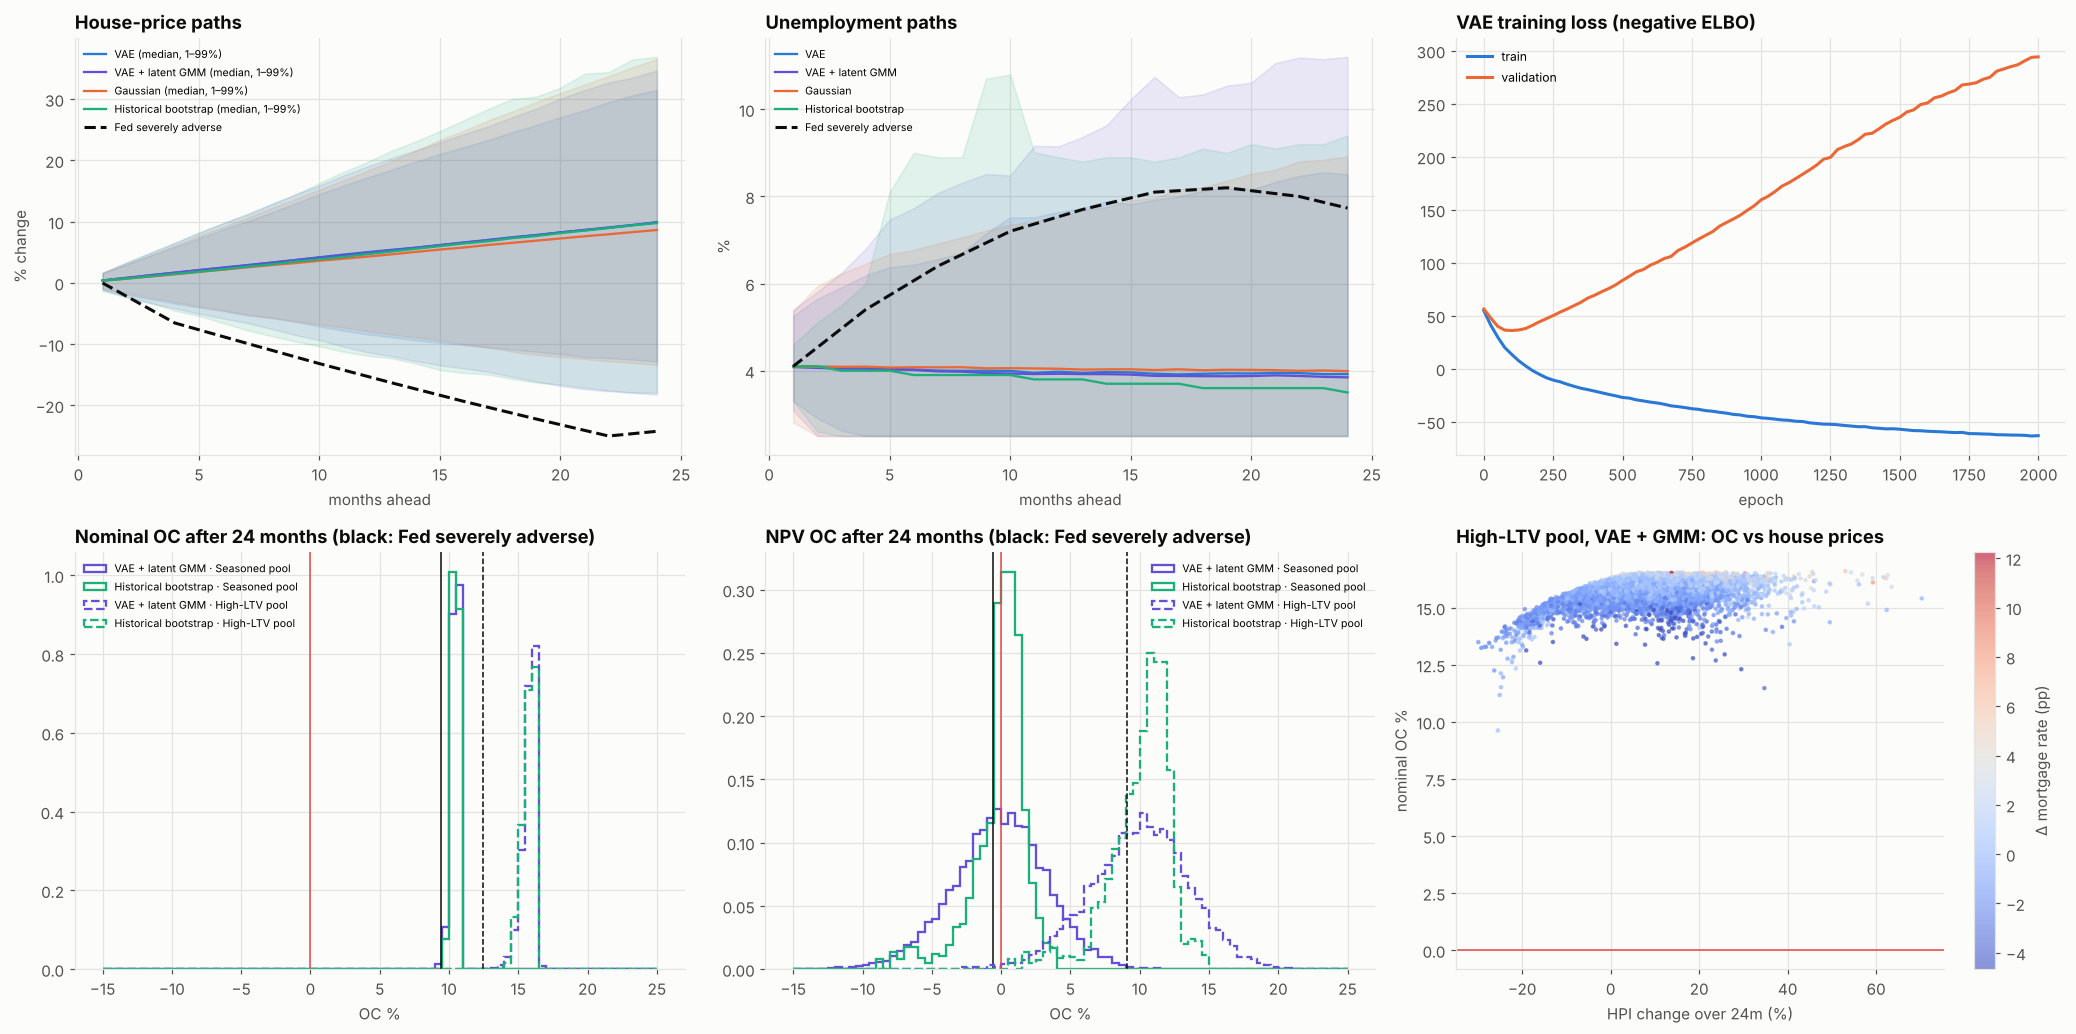

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(19, 9.5))
months = np.arange(1, WINDOW + 1)
cols = {
    "VAE": PALETTE[0],
    "VAE + latent GMM": PALETTE[6],
    "Gaussian": PALETTE[1],
    "Historical bootstrap": PALETTE[2],
}
ax = axes[0, 0]
for k, c in cols.items():
    q = np.percentile(
        gens[k][:, :, 0] / NOW["hpi"] * 100 - 100, [1, 50, 99], axis=0
    )
    ax.fill_between(months, q[0], q[2], color=c, alpha=0.12)
    ax.plot(months, q[1], color=c, lw=1.5, label=f"{k} (median, 1–99%)")
ax.plot(
    months,
    fed_path[0, :, 0] / NOW["hpi"] * 100 - 100,
    color=INK,
    ls="--",
    label="Fed severely adverse",
)
ax.set_title("House-price paths")
ax.set_xlabel("months ahead")
ax.set_ylabel("% change")
ax.legend(fontsize=7)
ax = axes[0, 1]
for k, c in cols.items():
    q = np.percentile(gens[k][:, :, 1], [1, 50, 99], axis=0)
    ax.fill_between(months, q[0], q[2], color=c, alpha=0.12)
    ax.plot(months, q[1], color=c, lw=1.5, label=k)
ax.plot(
    months, fed_path[0, :, 1], color=INK, ls="--", label="Fed severely adverse"
)
ax.set_title("Unemployment paths")
ax.set_xlabel("months ahead")
ax.set_ylabel("%")
ax.legend(fontsize=7)
ax = axes[0, 2]
ax.plot(hl.index, hl["train"], color=PALETTE[0], label="train")
ax.plot(hl.index, hl["validation"], color=PALETTE[1], label="validation")
ax.set_title("VAE training loss (negative ELBO)")
ax.set_xlabel("epoch")
ax.legend(fontsize=8)
PK = list(COHORTS)
ls_ = {PK[0]: "-", PK[1]: "--"}
for ax, col_, ttl in [
    (axes[1, 0], "nominal OC %", "Nominal OC after 24 months"),
    (axes[1, 1], "NPV OC %", "NPV OC after 24 months"),
]:
    for pk in PK:
        for gk, c in [
            ("VAE + latent GMM", PALETTE[6]),
            ("Historical bootstrap", PALETTE[2]),
        ]:
            v = results[pk][gk][24][col_]
            ax.hist(
                v,
                bins=np.linspace(-15, 25, 81),
                color=c,
                histtype="step",
                ls=ls_[pk],
                lw=1.5,
                density=True,
                label=f"{gk.split(' (')[0]} · {pk.split(' (')[0]}",
            )
        ax.axvline(
            results[pk]["Fed 2026 severely adverse"][24][col_].iloc[0],
            color=INK,
            ls=ls_[pk],
            lw=1,
        )
    ax.axvline(0, color=STATUS["red"], lw=1)
    ax.set_title(ttl + " (black: Fed severely adverse)")
    ax.set_xlabel("OC %")
    ax.legend(fontsize=7)
ax = axes[1, 2]
v24 = results[PK[1]]["VAE + latent GMM"][24]
sc = ax.scatter(
    v24["hpi change %"],
    v24["nominal OC %"],
    c=v24["mortgage rate change"],
    cmap="coolwarm",
    s=4,
    alpha=0.6,
)
plt.colorbar(sc, ax=ax, label="Δ mortgage rate (pp)")
ax.axhline(0, color=STATUS["red"], lw=1)
ax.set_title("High-LTV pool, VAE + GMM: OC vs house prices")
ax.set_xlabel("HPI change over 24m (%)")
ax.set_ylabel("nominal OC %")
plt.tight_layout()
save_fig(fig, "01_scenarios_and_oc")
plt.show()

## 8. Reading the results and limitations

**The two cover pools.**
- **Seasoned pool:** \$4.9bn of current 2018–23 loans, with a 4.55% weighted-average note rate and a 58% estimated current LTV.
- **High-LTV pool:** \$6.4bn of loans with ELTV ≥ 70% (23% of current loans; 5.78% average rate, 80% average ELTV).

The covered bond is a 5-year bullet at 4.88% (the 5-year Treasury at 4.38% plus 50 bp) with 10% nominal OC.

**With the crisis in the data, defaults rise steeply with LTV and unemployment.** On 20 million loan-months from 2005 to 2026, the monthly default hazard is 3–6 bp below 50% LTV, 24 bp at 80–90%, 71 bp at 100–110% and about 1.5% a month above 140%. The Poisson fit gives **+0.26 log points per 10 LTV points** and **+0.245 per point of unemployment** six months earlier, and 10.9 bp a month at 80% LTV with today's unemployment. On the 2018–26 Freddie Mac loans alone the slope was 0.18 and the unemployment effect had to be borrowed from a bank delinquency series (0.19).

**Generators.** History contains a 1-in-100 two-year house-price fall of 18% and an 11-point unemployment spike (COVID).

| Generator | House prices, 1st percentile | Unemployment, 99th-percentile rise | Mortgage–5y correlation |
|---|---|---|---|
| History | −18% | 11 pp | 0.92 |
| VAE, standard N(0,I) prior | −13% | 5 pp | 0.74 |
| Gaussian | −13% | 5 pp | 0.86 |
| VAE with latent GMM | −18% | 10.8 pp | 0.77 |
| Bootstrap | replays history | | |

- **The standard VAE and the Gaussian both understate tails.** The VAE's P(HPI falls more than 10%) is 2.3%, against 6.2% in history.
- **Sampling the VAE from a mixture fitted to the encoded history fixes the tails**, but the VAE still under-correlates mortgage rates with Treasuries.

**The held-out diagnostic is the warning label.** Validation loss is lowest after about 100 epochs and then rises steadily, so with 451 overlapping windows (about 18 independent episodes) the network mostly memorises. The refitted VAE behaves like a smoothed, recombined bootstrap rather than a model that has discovered new crises: useful, but no substitute for designed severe scenarios such as the Fed's (−24% house prices).

**Nominal OC is not where this book is at risk.**
- **Seasoned pool:** after 24 months nominal OC stays at about 10.5% in the median and above 9.6% in the worst 1% of every generator, and at 9.4% in the Fed scenario. The breakeven nominal OC is about 1%: at a 58% LTV the 80% cap almost never binds, and credit losses stay small even with the steeper crisis-calibrated hazard (99th percentile 0.2–0.3% of the pool over two years).
- **High-LTV pool:** OC *rises* to about 16%. Its 5.78% coupons exceed the 4.88% bond coupon, the surplus stays in the ring-fenced pool after the issuer's default, and amortisation brings loans back under the cap. Credit losses are larger (99th percentile 0.5–0.8%), and nominal OC falls towards 10–13% in the draws with the deepest house-price falls, but the breakeven stays negative: a regulatory minimum (2–5%) would bind instead.

**The NPV test is the binding constraint, and it is a rate problem.**
- **The seasoned pool fails the NPV test on day one.** Its 4.55% loans are worth well below par at today's 6.67% mortgage rate, so NPV OC is −2.1% at issuance despite 10% nominal OC.
- **Over 24 months, NPV OC is negative in 42–54% of scenarios.** Covering it in 99% of scenarios requires **16–19% initial OC** (17–20% at 99.5%).
- **The high-LTV pool needs only 6–9% (7–10% at 99.5%).** Its coupons are close to market, so its NPV OC starts at +7.8%.
- **Rates explain almost all of NPV OC** (R² 0.96 and 0.86). It falls 3.6–3.8 points per +1 pp in the mortgage rate and rises about 3 points per +1 pp in the 5-year yield, because the bond's own value falls.
- **The Fed's severely adverse scenario is benign for NPV.** Its mortgage rate *falls* by 0.7 pp, so it implies only an 11% and 2% requirement. A credit-only stress misses the risk that matters for a low-coupon book, which is the 2022–23 lesson (and SVB's).

**Limitations**
- **The cohorts flatten the loan-level LTV distribution.** Each of 100 cohorts carries one LTV, which understates the number of loans breaching the cap in a house-price fall.
- **One national house-price index drives the scenarios.** Regional dispersion (sand states in 2008) would hurt more than the national average.
- **The crisis hazard is borrowed across agencies and periods.** The crisis loans are Fannie Mae's 2005–08 acquisitions, their LTVs are rebuilt with state indices, and the hazard has no delinquency or loan-level terms beyond LTV and unemployment.
- **The behavioural models are simplified.** The prepayment S-curve is stylised, with no burnout or house-price effect on mobility; recoveries arrive after a fixed lag at a fixed haircut; cash earns nothing; and there is no asset sale at the bond's maturity, so refinancing risk is out of scope.
- **The NPV test uses simple discounting.** It discounts at the mortgage rate with a constant CPR, not an option-adjusted spread, and bonds at the 5-year Treasury plus a constant spread, although covered-bond spreads widen in stress.

In [12]:
gen_tab.to_csv(OUT_DIR / "generator_comparison.csv")
band_tab.to_csv(OUT_DIR / "default_hazard_by_ltv.csv")
oc_tab.to_csv(OUT_DIR / "oc_results.csv")
drivers.to_csv(OUT_DIR / "oc_drivers.csv")
pd.concat({k: v for k, v in COHORTS.items()}, names=["pool"]).to_csv(
    OUT_DIR / "cover_pool_cohorts.csv"
)
torch.save(vae.state_dict(), OUT_DIR / "vae_macro_scenarios.pt")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_scenarios_and_oc.png, cover_pool_cohorts.csv, default_hazard_by_ltv.csv, generator_comparison.csv, oc_drivers.csv, oc_results.csv, vae_macro_scenarios.pt


## References

### Finance and regulation

- European Parliament & Council of the European Union. (2019). *Directive (EU) 2019/2162 on the issue of covered bonds and covered bond public supervision*. https://eur-lex.europa.eu/eli/dir/2019/2162/oj
- European Parliament & Council of the European Union. (2013). *Regulation (EU) No 575/2013 on prudential requirements for credit institutions and investment firms* (Article 129). https://eur-lex.europa.eu/eli/reg/2013/575/oj
- Prokopczuk, M., Siewert, J. B., & Vonhoff, V. (2013). Credit risk in covered bonds. *Journal of Empirical Finance, 21*, 102–120. https://doi.org/10.1016/j.jempfin.2012.12.003
- Deng, Y., Quigley, J. M., & Van Order, R. (2000). Mortgage terminations, heterogeneity and the exercise of mortgage options. *Econometrica, 68*(2), 275–307. https://doi.org/10.1111/1468-0262.00110
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics, 17*(3), 1217–1241. https://doi.org/10.1214/aos/1176347265
- Fannie Mae. (2026). *Single-Family Loan Performance Data* [Data set]. https://capitalmarkets.fanniemae.com/credit-risk-transfer/single-family-credit-risk-transfer/fannie-mae-single-family-loan-performance-data

### Machine learning and deep learning

- Kingma, D. P., & Welling, M. (2014). Auto-encoding variational Bayes. In *Proceedings of the 2nd International Conference on Learning Representations*. https://arxiv.org/abs/1312.6114
- Buehler, H., Horvath, B., Lyons, T., Perez Arribas, I., & Wood, B. (2020). A data-driven market simulator for small data environments. *arXiv*. https://arxiv.org/abs/2006.14498
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703